# Forward vs backward Euler for the 1D heat equation

Companion notebook for Lecture 22 (`Lec22.tex`). We solve
$$
\frac{\partial u}{\partial t} = \frac{\partial^2 u}{\partial x^2} + f, \qquad (t, x) \in (0, T] \times (0, 1),
\qquad u(0, x) = c(x), \qquad u(t, 0) = u(t, 1) = 0,
$$
with the method of lines. On the grid $x_m = m \Delta x$, $m = 0, \dots, M$, $\Delta x = 1/M$, the centered
difference formula gives the ODE system
$$
\mathbf{u}'(t) = A \mathbf{u}(t) + \mathbf{f}(t), \qquad \mathbf{u}(0) = \mathbf{c},
\qquad A = \frac{1}{\Delta x^2}\,\mathrm{tridiag}(1, -2, 1) \in \mathbb{R}^{(M-1)\times(M-1)},
$$
which we integrate in time with
- forward Euler: $\mathbf{u}_{n+1} = \mathbf{u}_n + \Delta t \left( A \mathbf{u}_n + \mathbf{f}_n \right)$,
- backward Euler: $(I - \Delta t A)\, \mathbf{u}_{n+1} = \mathbf{u}_n + \Delta t\, \mathbf{f}_{n+1}$.

Forward Euler is only stable if $\Delta t \le \Delta x^2 / 2$ (approximately), while backward Euler is stable for any $\Delta t$.

In [1]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
import matplotlib.pyplot as plt

## Spatial discretization and time steppers

In [2]:
M = 50                          # number of spatial cells
dx = 1.0 / M
x = np.linspace(0, 1, M + 1)    # full grid including the boundary
xi = x[1:-1]                    # interior nodes x_1, ..., x_{M-1}
e = np.ones(M - 1)
A = sp.diags([e[:-1], -2 * e, e[:-1]], [-1, 0, 1], format="csc") / dx**2
print(f"M = {M}, dx = {dx}, forward Euler needs dt <= dx^2/2 = {dx**2 / 2:.1e}")


def forward_euler(c, f, T, N):
    """N steps of forward Euler for u' = A u + f(t), u(0) = c."""
    dt = T / N
    U = np.zeros((N + 1, M - 1))
    U[0] = c
    for n in range(N):
        U[n + 1] = U[n] + dt * (A @ U[n] + f(n * dt))
    return np.linspace(0, T, N + 1), U


def backward_euler(c, f, T, N):
    """N steps of backward Euler; the matrix I - dt A is factored once."""
    dt = T / N
    lu = splu((sp.identity(M - 1, format="csc") - dt * A).tocsc())
    U = np.zeros((N + 1, M - 1))
    U[0] = c
    for n in range(N):
        U[n + 1] = lu.solve(U[n] + dt * f((n + 1) * dt))
    return np.linspace(0, T, N + 1), U


def with_boundary(U):
    """Append the zero Dirichlet boundary values u_0 = u_M = 0."""
    return np.pad(U, ((0, 0), (1, 1)))

M = 50, dx = 0.02, forward Euler needs dt <= dx^2/2 = 2.0e-04


## Case 1: $f = 0$, initial condition a mixture of a skinny and a wide Gaussian

The skinny Gaussian contains a lot of high frequency content, i.e., large components along the
eigenvectors $\mathbf{q}_k$ of $A$ with large $|\lambda_k|$. These are exactly the modes that forward Euler
amplifies when $\Delta t$ is too large.

In [3]:
def gaussian(x, mu, sigma):
    return np.exp(-(x - mu) ** 2 / (2 * sigma**2))


c = gaussian(xi, 0.3, 0.03) + 0.6 * gaussian(xi, 0.6, 0.12)
zero = lambda t: 0.0
T = 0.1

runs = {
    "BE": backward_euler(c, zero, T, 100),    # dt = 1e-3,     dt/dx^2 = 2.5
    "FE stable": forward_euler(c, zero, T, 520),     # dt/dx^2 ~ 0.48
    "FE unstable": forward_euler(c, zero, T, 493),   # dt/dx^2 ~ 0.507
}
for name, (t, U) in runs.items():
    dt = t[1] - t[0]
    print(f"{name:12s} dt = {dt:.3e}, dt/dx^2 = {dt / dx**2:.3f}, max|u(T)| = {abs(U[-1]).max():.3e}")

# forward Euler with the same (large) time step as backward Euler blows up completely
t, U = forward_euler(c, zero, T, 100)
print(f"FE with dt = 1e-3:  max|u(T)| = {abs(U[-1]).max():.3e}")

BE           dt = 1.000e-03, dt/dx^2 = 2.500, max|u(T)| = 1.652e-01
FE stable    dt = 1.923e-04, dt/dx^2 = 0.481, max|u(T)| = 1.642e-01
FE unstable  dt = 2.028e-04, dt/dx^2 = 0.507, max|u(T)| = 2.203e+00
FE with dt = 1e-3:  max|u(T)| = 2.424e+90


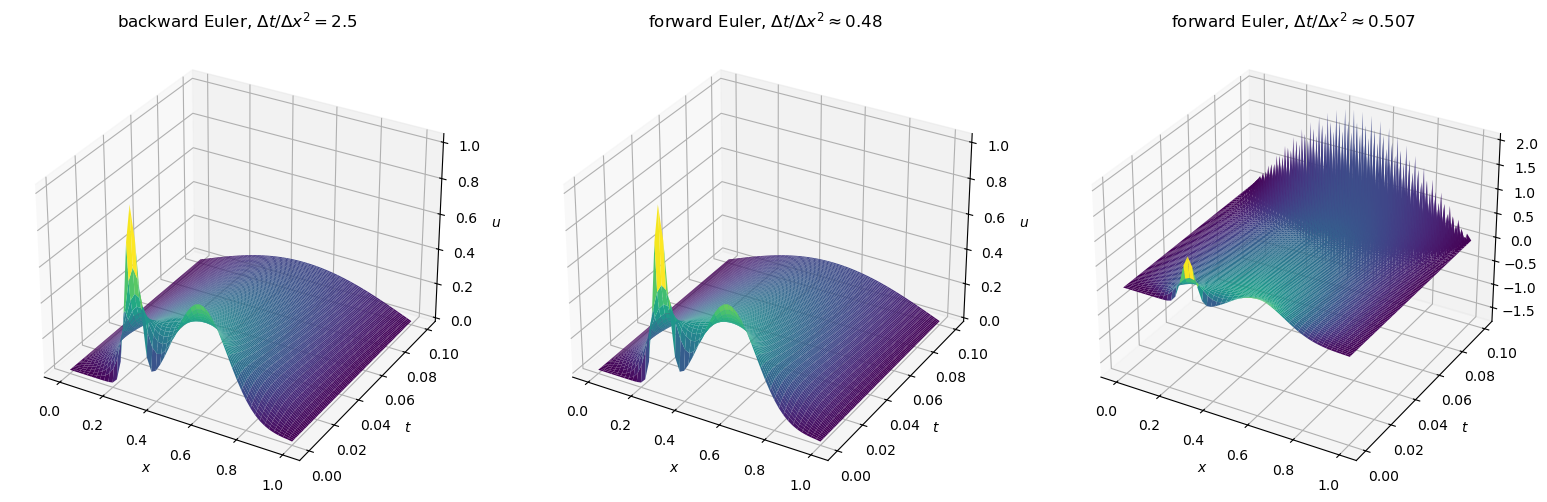

In [4]:
def surface(ax, t, U, stride, title, zlim=None):
    X, Tt = np.meshgrid(x, t[::stride])
    ax.plot_surface(X, Tt, with_boundary(U)[::stride], cmap="viridis",
                    rstride=1, cstride=1, linewidth=0, antialiased=True)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$t$")
    ax.set_zlabel("$u$")
    ax.set_title(title)
    if zlim is not None:
        ax.set_zlim(*zlim)
    ax.view_init(elev=30, azim=-60)


fig = plt.figure(figsize=(16, 5))
titles = {
    "BE": "backward Euler, $\\Delta t / \\Delta x^2 = 2.5$",
    "FE stable": "forward Euler, $\\Delta t / \\Delta x^2 \\approx 0.48$",
    "FE unstable": "forward Euler, $\\Delta t / \\Delta x^2 \\approx 0.507$",
}
for k, (name, (t, U)) in enumerate(runs.items()):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    stride = max(1, len(t) // 100) | 1    # odd stride keeps the sign flips of the unstable mode visible
    surface(ax, t, U, stride, titles[name])
fig.tight_layout()
fig.savefig("heat_fe_vs_be.png", dpi=200, bbox_inches="tight")
plt.show()

Backward Euler and the stable forward Euler run agree, even though backward Euler takes about five times
fewer steps. Increasing the forward Euler step by less than 6% (from $\Delta t/\Delta x^2 \approx 0.48$ to $0.507$)
pushes $1 + \Delta t \lambda_{M-1}$ below $-1$: the highest frequency mode $\mathbf{q}_{M-1}$ (a zigzag on the grid)
changes sign and grows at every step, and eventually swamps the solution. With $\Delta t = 10^{-3}$, the step used by
backward Euler, forward Euler reaches values around $10^{90}$.

## Case 2: a nontrivial source term

Now take $f(x)$ to be a time independent mixture of three Gaussians, two positive (heating) and one negative
(cooling), and keep the same initial condition. We only use backward Euler here, with a large time step. As
$t \to \infty$ the solution approaches the steady state $u_\infty$ that solves the BVP $-u_\infty'' = f$,
$u_\infty(0) = u_\infty(1) = 0$, which we can compute by solving $A \mathbf{u}_\infty = -\mathbf{f}$.

max |u(T) - u_inf| = 2.52e-03


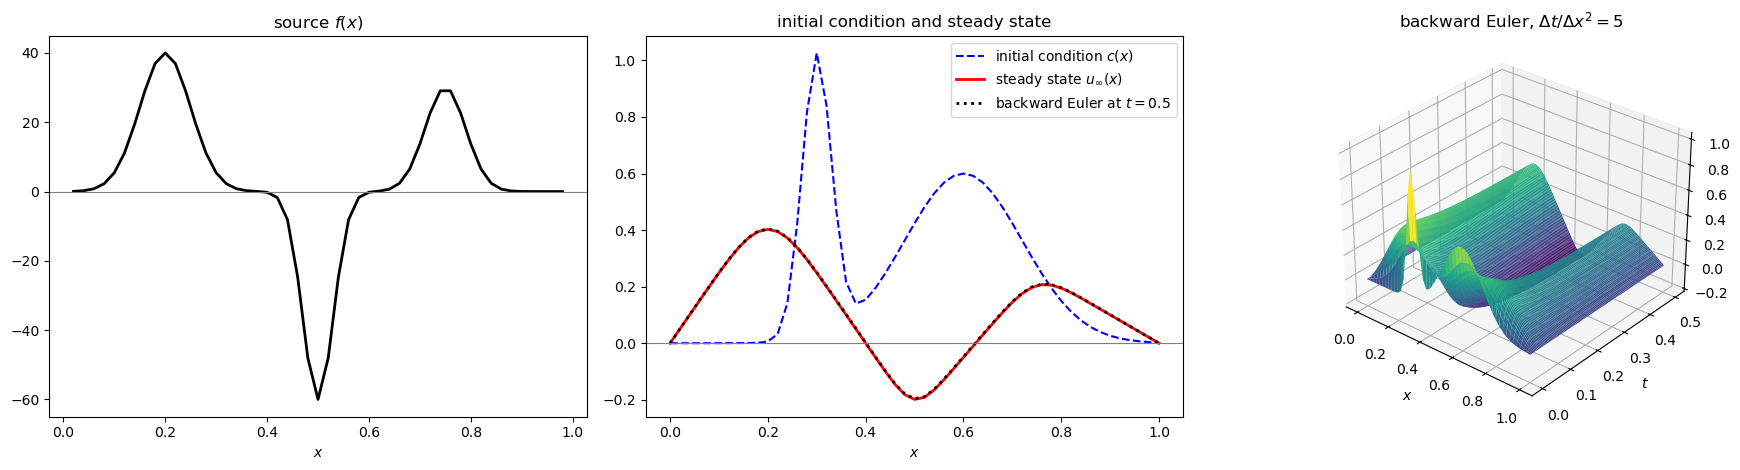

In [5]:
f_x = 40 * gaussian(xi, 0.2, 0.05) + 30 * gaussian(xi, 0.75, 0.04) - 60 * gaussian(xi, 0.5, 0.03)
source = lambda t: f_x

T2 = 0.5
t2, U2 = backward_euler(c, source, T2, 250)    # dt = 2e-3, dt/dx^2 = 5
u_inf = splu(A).solve(-f_x)
print(f"max |u(T) - u_inf| = {abs(U2[-1] - u_inf).max():.2e}")

fig = plt.figure(figsize=(18, 4.8))
ax1 = fig.add_subplot(1, 3, 1)
ax1.plot(xi, f_x, "k-", lw=2)
ax1.axhline(0, color="gray", lw=0.8)
ax1.set_xlabel("$x$")
ax1.set_title("source $f(x)$")

ax2 = fig.add_subplot(1, 3, 2)
ax2.plot(x, np.pad(c, 1), "b--", lw=1.5, label="initial condition $c(x)$")
ax2.plot(x, np.pad(u_inf, 1), "r-", lw=2, label="steady state $u_\\infty(x)$")
ax2.plot(x, np.pad(U2[-1], 1), "k:", lw=2, label=f"backward Euler at $t = {T2}$")
ax2.axhline(0, color="gray", lw=0.8)
ax2.set_xlabel("$x$")
ax2.legend(loc="upper right")
ax2.set_title("initial condition and steady state")

ax3 = fig.add_subplot(1, 3, 3, projection="3d")
surface(ax3, t2, U2, 2, "backward Euler, $\\Delta t / \\Delta x^2 = 5$")
ax3.view_init(elev=30, azim=-50)
fig.tight_layout()
fig.savefig("heat_forced.png", dpi=200, bbox_inches="tight")
plt.show()